# Task 1: a model that predicts what a signup is worth (standalone notebook)

**How to read this.** Text cells explain what we do and why, in plain language. Code cells do it. The table or chart under a code cell is its result. You do not need to read the code to follow the story.

This notebook is self-contained: it needs only pandas, numpy, scikit-learn and matplotlib (all preinstalled on Google Colab) and the case file `fonio_case_signups.csv`, which it loads from the repository if it is not next to the notebook. Every number and chart is computed here, nothing is loaded from saved results.

**The question.** Meta and Google Ads optimise for signups. Some signups never connect a phone number, others pay for months. We want to tell the platforms, 72 hours after each signup, how much that signup is probably worth in euros.

**The answer.** We built one model for Meta signups and one for Google Ads signups. On two months the models were not trained on, the 30% of signups with the highest predicted value brought in about **85% of Meta's revenue** and **74% of Google Ads' revenue**. Today, when every signup counts the same, 30% of signups bring 30% of revenue.

Sections: **0 Data · 1 Which features we use and which we leave out · 2 Build the model · 3 When we score · 4 How we validated it · 5 Other checks · 6 Decisions.**

In [1]:
import os, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
pd.set_option("display.width", 140); pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
BLUE, BLUE2, BLUE3, ORANGE, GRAY, INK, INK2 = "#2a78d6", "#6ea6e6", "#c7dcf5", "#eb6834", "#9a9892", "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white"})

CSV = "../data/fonio_case_signups.csv"
if not os.path.exists(CSV):   # e.g. on Google Colab: read the file straight from the repository
    CSV = "https://raw.githubusercontent.com/Danila-kach/fonio-lead-value/main/data/fonio_case_signups.csv"

df = pd.read_csv(CSV)
df["signup_date"] = pd.to_datetime(df["signup_date"])
df["signup_dow"] = df["signup_date"].dt.dayofweek
for c in ["business_email", "phone_connected_24h", "assistant_configured_24h", "calendar_connected_72h", "onboarding_call_booked", "converted_paid_30d"]:
    df[c] = df[c].astype(str).str.lower().eq("true").astype(int)
print(f"{len(df):,} signups from {df.signup_date.min().date()} to {df.signup_date.max().date()}")
df.head(3)

6,000 signups from 2025-10-01 to 2026-03-31


,signup_id,signup_date,signup_hour,channel,country,industry,company_size,device,business_email,phone_connected_24h,assistant_configured_24h,test_calls_72h,calendar_connected_72h,onboarding_call_booked,minutes_used_7d,plan_selected,days_to_first_payment,converted_paid_30d,revenue_180d_eur,signup_dow
0,S100380,2025-10-01,6,meta,DE,medical,2-5,mobile,1,0,1,1,0,0,0.00,none,NaN,0,0.00,2
1,S104690,2025-10-01,15,meta,DE,automotive,2-5,mobile,1,0,0,0,0,1,0.00,none,NaN,0,0.00,2
2,S102645,2025-10-01,18,meta,DE,trades,2-5,desktop,0,1,0,0,0,0,18.10,none,NaN,0,0.00,2


## 0. What the data looks like

One row per signup. For each signup we know what the person told us in the form (country, industry, company size), what the browser told us (device, channel), what they did in the product in the first days (phone connected, assistant set up, test calls, calendar), and what happened afterwards (did they pay within 30 days, how much they paid over 180 days).

In [2]:
by_channel = df.groupby("channel").agg(signups=("signup_id","size"), share_of_signups=("signup_id", lambda s: len(s)/len(df)),
    paid_within_30d=("converted_paid_30d","mean"), revenue_180d_per_signup=("revenue_180d_eur","mean")).sort_values("signups", ascending=False)
by_channel.style.format({"share_of_signups": "{:.0%}", "paid_within_30d": "{:.0%}", "revenue_180d_per_signup": "€{:.0f}"})

,signups,share_of_signups,paid_within_30d,revenue_180d_per_signup
channel,,,,
meta,2555,43%,16%,€101
google_search,1519,25%,38%,€326
google_pmax,773,13%,26%,€181
organic,703,12%,31%,€242
referral,450,8%,34%,€298


Meta brings 43% of all signups, but a Meta signup is worth about € 101 over 180 days, against € 326 for a Google Search signup. Only 16% of Meta signups pay. The job of the model is to find those 16% early.

**What "revenue over 180 days" is.** In this dataset it is exactly *plan price × number of months the customer stayed* (1 to 6 months). So it already rewards customers who stay: a cheap plan kept for 6 months is worth more than an expensive plan dropped after one month. The three plans in the dataset cost € 49, € 99 and € 249 per month (synthetic prices).

In [3]:
payers = df[df.converted_paid_30d == 1]
payers.groupby("plan_selected").revenue_180d_eur.agg(["min", "max", "mean"]).rename(columns={"min": "1 month", "max": "6 months", "mean": "average"}).style.format("€{:.0f}")

,1 month,6 months,average
plan_selected,,,
business,€249,€1494,€1133
pro,€99,€594,€400
starter,€49,€294,€191


## 1. Which features we use, and which we leave out

Before building anything we decide what the model is allowed to see. The rule: **only what our database shows 72 hours after signup.**

**Used, exactly as the columns are named in the table:** `country`, `industry`, `company_size`, `device`, `business_email`, `signup_hour`, `signup_date` (as weekday), `phone_connected_24h`, `assistant_configured_24h`, `test_calls_72h`, `calendar_connected_72h`.

**Plus two features of our own:** `paid_by_72h` = True if `days_to_first_payment` ≤ 3, otherwise False; `plan_by_72h` = `plan_selected` for those signups, `none` for everyone else. In the data every payer has a plan and every plan has a payment, so the two always match.

**Left out:**

In [4]:
EXCLUDED = {
    "minutes_used_7d": "not known before 72 hours (needs 7 days)",
    "converted_paid_30d": "not known before 72 hours (this is one of the answers the model learns to predict)",
    "revenue_180d_eur": "not known before 72 hours (the other answer)",
    "onboarding_call_booked": "no timestamp, so we cannot tell whether it happened before or after 72h",
    "signup_id": "an ID",
    "plan_selected": "filled in only when the payment happens; used only to build plan_by_72h",
    "days_to_first_payment": "filled in only when the payment happens; used only to build paid_by_72h",
}
pd.Series(EXCLUDED, name="why it is left out").to_frame()

,why it is left out
minutes_used_7d,not known before 72 hours (needs 7 days)
converted_paid_30d,not known before 72 hours (this is one of the ...
revenue_180d_eur,not known before 72 hours (the other answer)
onboarding_call_booked,"no timestamp, so we cannot tell whether it hap..."
signup_id,an ID
plan_selected,filled in only when the payment happens; used ...
days_to_first_payment,filled in only when the payment happens; used ...


**Why `plan_selected` and `days_to_first_payment` are left out.** They are filled in when the payment happens, and at 72 hours only 3% of signups have paid. In production the model would see `none` and an empty date for 97% of new signups and would rate almost all of them as worthless. The table below shows why they look so tempting in the file: plan and payment match row for row.

In [5]:
print(pd.crosstab(df.plan_selected, df.converted_paid_30d.map({0: "did not pay", 1: "paid"})))
d = df.days_to_first_payment
print(f"\npayers: {int(df.converted_paid_30d.sum())}  |  already paid by 24h: {int(d.le(1).sum())}  |  by 72h: {int(d.le(3).sum())}  |  by day 7: {int(d.le(7).sum())}")

converted_paid_30d  did not pay  paid
plan_selected                        
business                      0   844
none                       4441     0
pro                           0   498
starter                       0   217

payers: 1559  |  already paid by 24h: 58  |  by 72h: 152  |  by day 7: 359


**Which signups go into which model.** We only ever send values to two places: Meta and Google Ads. The same onboarding behaviour pays less from Meta than from Google: a Meta signup that connected the calendar pays 46% of the time, a Google Search signup 67%. So we build **two models**, one on Meta signups and one on Google Ads signups (`google_search` + `google_pmax`, two campaign types of the same account bidding on the same conversion action). **Organic and referral signups are not used at all**: there is no platform to send their value to. Section 5 shows that mixing all channels into one model does not help.

channel,google_pmax,google_search,meta,organic,referral
behaviour,,,,,
1 nothing in the first 24h,7%,11%,4%,8%,5%
"2 phone connected, no calendar",27%,31%,21%,27%,30%
3 calendar connected by 72h,53%,67%,46%,59%,62%


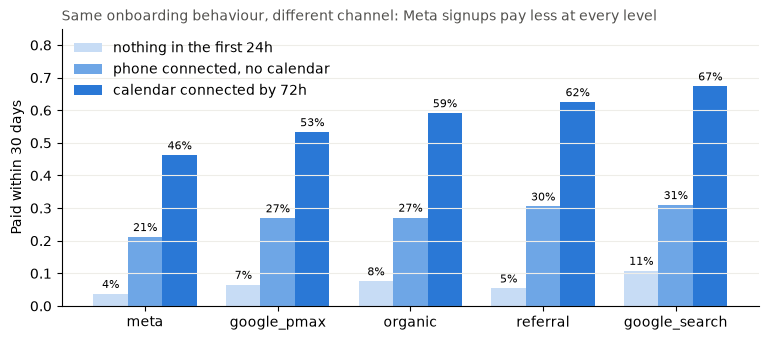

In [6]:
seg = np.select([df.calendar_connected_72h.eq(1), df.phone_connected_24h.eq(1)], ["3 calendar connected by 72h", "2 phone connected, no calendar"], "1 nothing in the first 24h")
piv = pd.pivot_table(df.assign(behaviour=seg), index="behaviour", columns="channel", values="converted_paid_30d", aggfunc="mean")
display(piv.style.format("{:.0%}"))

order = ["meta", "google_pmax", "organic", "referral", "google_search"]
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(len(order)); w = 0.26
for i, (s, col) in enumerate(zip(piv.index, [BLUE3, BLUE2, BLUE])):
    vals = [piv.loc[s, c] for c in order]
    bars = ax.bar(x + (i - 1) * w, vals, w, color=col, label=s[2:])
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.0%}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, order); ax.set_ylim(0, 0.85); ax.set_ylabel("Paid within 30 days"); ax.legend(frameon=False, loc="upper left"); ax.grid(axis="y", color="#eeede8")
ax.set_title("Same onboarding behaviour, different channel: Meta signups pay less at every level", loc="left", color=INK2, fontsize=10); plt.show()

### The code that builds the features

Everything the model sees at 24h or 72h, built from the table. Categorical columns are turned into 0/1 columns (one per value).

In [7]:
HORIZON_DAYS = {"24h": 1, "72h": 3}
BASE_CATEGORICAL = ["country", "industry", "company_size", "device", "channel"]
BASE_NUMERIC = ["business_email", "signup_hour", "signup_dow"]
FEATURES_BY_HORIZON = {"24h": ["phone_connected_24h", "assistant_configured_24h", "paid_by_h", "plan_by_h"],
                       "72h": ["phone_connected_24h", "assistant_configured_24h", "test_calls_72h", "calendar_connected_72h", "paid_by_h", "plan_by_h"]}
TRAIN_END = pd.Timestamp("2026-02-01")           # train: Oct-Jan, test: Feb-Mar
CHANNEL_GROUPS = {"meta": ["meta"], "google": ["google_search", "google_pmax"]}

def add_horizon_features(df, horizon):
    out = df.copy()
    paid_by = out["days_to_first_payment"].le(HORIZON_DAYS[horizon]).fillna(False)
    out["paid_by_h"] = paid_by.astype(int)
    out["plan_by_h"] = out["plan_selected"].where(paid_by, "none")
    return out

def feature_frame(df, horizon, include_channel=True):
    d = add_horizon_features(df, horizon)
    cats = [c for c in BASE_CATEGORICAL if include_channel or c != "channel"] + ["plan_by_h"]
    nums = BASE_NUMERIC + [c for c in FEATURES_BY_HORIZON[horizon] if c != "plan_by_h"]
    return pd.get_dummies(d[cats + nums], columns=cats, dtype=float)

def split_by_time(df):
    train = (df["signup_date"] < TRAIN_END).values
    return train, ~train

def channel_mask(df, group):
    return df["channel"].isin(CHANNEL_GROUPS[group]).values

X72 = feature_frame(df, "72h")
print("feature columns at 72h:", X72.shape[1]); list(X72.columns)

feature columns at 72h: 33


['business_email',
 'signup_hour',
 'signup_dow',
 'phone_connected_24h',
 'assistant_configured_24h',
 'test_calls_72h',
 'calendar_connected_72h',
 'paid_by_h',
 'country_AT',
 'country_CH',
 'country_DE',
 'industry_automotive',
 'industry_beauty',
 'industry_hospitality',
 'industry_medical',
 'industry_other',
 'industry_property_mgmt',
 'industry_trades',
 'company_size_1',
 'company_size_2-5',
 'company_size_21+',
 'company_size_6-20',
 'device_desktop',
 'device_mobile',
 'channel_google_pmax',
 'channel_google_search',
 'channel_meta',
 'channel_organic',
 'channel_referral',
 'plan_by_h_business',
 'plan_by_h_none',
 'plan_by_h_pro',
 'plan_by_h_starter']

## 2. Build the model

### How the model works, in plain words

A model is a formula. It takes the facts we know about a signup 72 hours in and turns them into one number: expected revenue in euros.

**Training** is how the formula gets its numbers. We give the computer the signups from October to January as a *worked answer key*: for each one, the facts at 72h **and** the outcome (`converted_paid_30d` and `revenue_180d_eur`). Those two outcome columns are only used as the answers to learn from. They are never used as inputs, because in real life they do not exist yet when we score.

**Two steps.** 74% of signups bring € 0 (only 26% ever pay), so one formula for the euro amount would mostly be guessing zeros. We split the question:

1. **Will this signup pay within 30 days?** A *logistic regression*: every fact gets a weight (phone connected: +0.8, solo company: −0.2, ...), the weights are added up, and the sum is turned into a probability between 0 and 1. The computer finds the weights by comparing the training signups that paid with those that did not, adjusting thousands of times until the error stops shrinking.
2. **If they pay, how much over 180 days?** A second formula with its own weights, trained **only on the training signups that did pay** (we know which ones from the answer key), comparing those who brought more with those who brought less.

**Value = (chance of paying) × (revenue if they pay).** A signup with a 55% chance of paying and € 900 expected if they pay is worth € 495. A signup with a 3% chance and € 400 is worth € 12.

In [8]:
class LeadValueModel:
    def __init__(self, stage1="logreg", stage2="ridge"):
        self.stage1_name, self.stage2_name = stage1, stage2
        self.clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)) if stage1 == "logreg" \
            else HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, l2_regularization=1.0)
        if stage2 == "ridge":   self.reg = make_pipeline(StandardScaler(), Ridge(alpha=5.0))
        elif stage2 == "gbm":   self.reg = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200)
        else:                   self.reg = None          # one-step variant: one average revenue for every payer
        self.columns, self.mean_payer_revenue, self.min_payer_revenue = None, np.nan, 0.0

    def fit(self, X, y_paid, y_rev):
        self.columns = list(X.columns)
        self.clf.fit(X, y_paid)
        payers = y_paid == 1
        self.mean_payer_revenue, self.min_payer_revenue = float(y_rev[payers].mean()), float(y_rev[payers].min())
        if self.reg is not None: self.reg.fit(X[payers], y_rev[payers])
        return self

    def _align(self, X): return X.reindex(columns=self.columns, fill_value=0.0)

    def explain(self, X):
        X = self._align(X)
        p = self.clf.predict_proba(X)[:, 1]
        rev = np.full(len(X), self.mean_payer_revenue) if self.reg is None else np.clip(self.reg.predict(X), self.min_payer_revenue, None)
        return pd.DataFrame({"p_pay": p, "revenue_if_pays": rev, "value": p * rev}, index=X.index)

    def predict_value(self, X): return self.explain(X)["value"].values

    def coefficients(self):           # step 1 weights
        return pd.Series(self.clf.named_steps["logisticregression"].coef_[0], index=self.columns)

    def coefficients_stage2(self):    # step 2 weights, in euros
        return pd.Series(self.reg.named_steps["ridge"].coef_, index=self.columns)

# the checks a marketer would understand
def revenue_captured(score, revenue, top_share=0.3):
    order = np.argsort(-score, kind="stable"); rev = revenue[order]
    cum = np.cumsum(rev) / rev.sum(); share = np.arange(1, len(rev) + 1) / len(rev)
    return float(np.interp(top_share, share, cum))

def gain_curve(score, revenue, points=100):
    order = np.argsort(-score, kind="stable"); rev = revenue[order]
    cum = np.cumsum(rev) / rev.sum(); share = np.arange(1, len(rev) + 1) / len(rev)
    grid = np.linspace(0, 1, points + 1)[1:]; return grid, np.interp(grid, share, cum)

def thirds(score, paid, revenue):
    q = pd.qcut(pd.Series(score).rank(method="first"), 3, labels=["bottom", "middle", "top"])
    d = pd.DataFrame({"third": q.values, "paid": paid, "revenue": revenue, "score": score})
    t = d.groupby("third", observed=True).agg(signups=("paid", "size"), paid_within_30d=("paid", "mean"),
                                              real_revenue_per_signup=("revenue", "mean"), predicted_value_per_signup=("score", "mean"))
    return t.loc[["top", "middle", "bottom"]]

def calibration(score, revenue, bins=5):
    q = pd.qcut(pd.Series(score).rank(method="first"), bins, labels=False)
    return pd.DataFrame({"bin": q, "model_said": score, "really_brought": revenue}).groupby("bin").agg(signups=("model_said", "size"), model_said=("model_said", "mean"), really_brought=("really_brought", "mean"))

def summary(score, paid, revenue):
    return {"signups": int(len(score)), "auc": float(roc_auc_score(paid, score)), "revenue_top30": revenue_captured(score, revenue, 0.3),
            "revenue_top50": revenue_captured(score, revenue, 0.5), "predicted_mean": float(np.mean(score)), "actual_mean": float(np.mean(revenue))}
print("model and checks defined")

model and checks defined


### Train: one model per platform, on October 2025 – January 2026

February and March 2026 are kept aside and never shown to the models. That mirrors production, where the model always scores future signups.

In [9]:
y_paid, y_rev = df.converted_paid_30d.values, df.revenue_180d_eur.values
train, test = split_by_time(df)
models, scores, test_mask = {}, {}, {}
for platform in ["meta", "google"]:
    tr, te = train & channel_mask(df, platform), test & channel_mask(df, platform)
    models[platform] = LeadValueModel("logreg", "ridge").fit(X72[tr], y_paid[tr], y_rev[tr])
    scores[platform], test_mask[platform] = models[platform].predict_value(X72[te]), te
    print(f"{platform:7s} trained on {tr.sum():,} signups ({int(y_paid[tr].sum())} of them paid); kept {te.sum():,} Feb-Mar signups for testing")

meta    trained on 1,753 signups (282 of them paid); kept 802 Feb-Mar signups for testing
google  trained on 1,534 signups (510 of them paid); kept 758 Feb-Mar signups for testing


### Three real signups from the test months, scored by the Meta model

`p_pay` is step 1, `revenue_if_pays` is step 2, `value` is what we would send to Meta. None of the three had paid by 72h, so the model judged them on behaviour alone. The last two columns show what really happened; single signups always vary, the test of the model is whether groups of signups average out (section 4).

In [10]:
te = test_mask["meta"]; ex = models["meta"].explain(X72[te]); raw = df.loc[te]
not_paid_yet = (raw.days_to_first_payment.isna() | raw.days_to_first_payment.gt(3)).values
v = ex.loc[not_paid_yet, "value"]
picks = {"high": v.idxmax(), "median": v.sort_values().index[len(v)//2], "low": v.idxmin()}
cols = ["industry","company_size","device","business_email","phone_connected_24h","assistant_configured_24h","test_calls_72h","calendar_connected_72h"]
out = pd.concat([raw.loc[list(picks.values()), cols], ex.loc[list(picks.values())].round(3), raw.loc[list(picks.values()), ["converted_paid_30d","revenue_180d_eur"]]], axis=1)
out.index = list(picks.keys()); out.T

,high,median,low
industry,trades,other,automotive
company_size,6-20,1,1
device,desktop,mobile,mobile
business_email,1,0,0
phone_connected_24h,1,1,0
assistant_configured_24h,1,0,1
test_calls_72h,9,0,0
calendar_connected_72h,0,0,0
p_pay,0.93,0.05,0.00
revenue_if_pays,864.93,408.57,136.43


## 3. When we score: 24 hours or 72 hours?

The earlier we score, the sooner the platform gets the signal, but the less we know. At 24h we know phone and assistant; at 72h we also see test calls, the calendar and any very early payment. Both moments fit the platforms' windows (Meta Conversions API accepts events up to 7 days old; Google Ads accepts conversions inside the action's window, which we set to 30 days). The question is how much accuracy we gain by waiting.

scored at,24h,72h
platform,,
google,65%,74%
meta,81%,85%


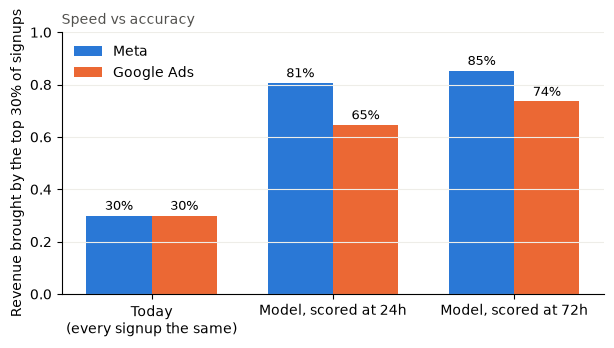

In [11]:
rows = []
for platform in ["meta","google"]:
    for h in ["24h","72h"]:
        X = feature_frame(df, h); tr, te = train & channel_mask(df, platform), test & channel_mask(df, platform)
        s = LeadValueModel().fit(X[tr], y_paid[tr], y_rev[tr]).predict_value(X[te])
        rows.append({"platform": platform, "scored at": h, "revenue in top 30%": revenue_captured(s, y_rev[te])})
hz = pd.DataFrame(rows).pivot(index="platform", columns="scored at", values="revenue in top 30%")
display(hz.style.format("{:.0%}"))

fig, ax = plt.subplots(figsize=(7, 3.4)); x = np.arange(3); w = 0.36
for i, platform in enumerate(["meta", "google"]):
    vals = [0.30, hz.loc[platform, "24h"], hz.loc[platform, "72h"]]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, color=[BLUE, ORANGE][i], label={"meta": "Meta", "google": "Google Ads"}[platform])
    for b, val in zip(bars, vals): ax.text(b.get_x() + b.get_width()/2, val + 0.01, f"{val:.0%}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, ["Today\n(every signup the same)", "Model, scored at 24h", "Model, scored at 72h"]); ax.set_ylim(0, 1)
ax.set_ylabel("Revenue brought by the top 30% of signups"); ax.legend(frameon=False, loc="upper left"); ax.grid(axis="y", color="#eeede8")
ax.set_title("Speed vs accuracy", loc="left", color=INK2, fontsize=10); plt.show()

**Decision: score at 72 hours.** Waiting two more days adds about 4 points on Meta and 9 points on Google.

## 4. How we validated it, and how much better it is than treating every signup the same

The file holds six months of signups with known outcomes. We built the models on the first four months (October 2025 to January 2026) and kept the last two (February and March 2026) aside. The split follows time, as in production: the model learns from the past and is applied to what comes next. Four months give enough examples to learn from (280 Meta payers), two months give enough to judge (802 Meta signups). The models then predicted a value for every February-March signup, and we compared it with the real `converted_paid_30d` and `revenue_180d_eur`.

**What "treating every signup the same" means.** That is today's setup: every signup is worth the same to the platform. If you pick any 30% of signups, you get, on average, 30% of the revenue.

### 4a. Revenue brought by the 30% of signups with the highest predicted value

Rank the test signups by predicted value, take the top 30%, add up the revenue they really brought, divide by the revenue of all test signups.

*A small example:* ten signups whose real revenue is € 500, € 300, € 150, € 50 and six times € 0, € 1,000 in total. Any three picked at random bring about € 300 (30%). If the model's top three are the € 500, € 300 and € 150 signups, they bring € 950 (95%). The closer to 100%, the better the model sorts the money to the top.

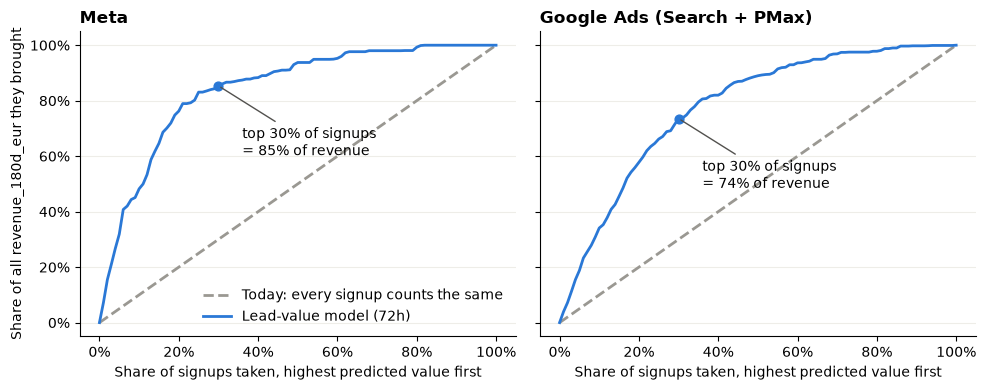

In [12]:
rows = []
for platform in ["meta","google"]:
    te = test_mask[platform]
    random_order = np.random.default_rng(0).random(te.sum())   # "today": no ranking, any order is as good as any other
    for name, s in [("today: every signup the same", random_order), ("lead-value model (72h)", scores[platform])]:
        r = summary(s, y_paid[te], y_rev[te]); r["platform"], r["scoring"] = platform, name; rows.append(r)
display(pd.DataFrame(rows).set_index(["platform","scoring"])[["signups","revenue_top30","revenue_top50","predicted_mean","actual_mean"]]
        .style.format({"revenue_top30": "{:.0%}", "revenue_top50": "{:.0%}", "predicted_mean": "€{:.0f}", "actual_mean": "€{:.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (platform, title) in zip(axes, [("meta", "Meta"), ("google", "Google Ads (Search + PMax)")]):
    te = test_mask[platform]; grid, cum = gain_curve(scores[platform], y_rev[te])
    ax.plot([0, 1], [0, 1], color=GRAY, lw=2, ls="--", label="Today: every signup counts the same")
    ax.plot(np.r_[0, grid], np.r_[0, cum], color=BLUE, lw=2, label="Lead-value model (72h)")
    v = revenue_captured(scores[platform], y_rev[te]); ax.scatter([0.3], [v], color=BLUE, s=40, zorder=3)
    ax.annotate(f"top 30% of signups\n= {v:.0%} of revenue", (0.3, v), xytext=(0.36, v - 0.25), arrowprops=dict(arrowstyle="-", color=INK2))
    ax.set_title(title, loc="left", fontweight="bold"); ax.set_xlabel("Share of signups taken, highest predicted value first"); ax.grid(axis="y", color="#eeede8")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("Share of all revenue_180d_eur they brought"); axes[0].legend(loc="lower right", frameon=False); plt.tight_layout(); plt.show()

The chart shows the same thing for every cut-off, not only 30%. The dashed diagonal is today. The blue line is the model.

### 4b. Split the test signups into thirds by predicted value

If the model works, the top third should pay far more often and bring far more money than the bottom third.

--- meta ---


,signups,paid_within_30d,real_revenue_per_signup,predicted_value_per_signup
third,,,,
top,267,39%,€270,€247
middle,267,9%,€33,€28
bottom,268,2%,€7,€5


--- google ---


,signups,paid_within_30d,real_revenue_per_signup,predicted_value_per_signup
third,,,,
top,253,73%,€666,€650
middle,252,25%,€159,€167
bottom,253,8%,€42,€28


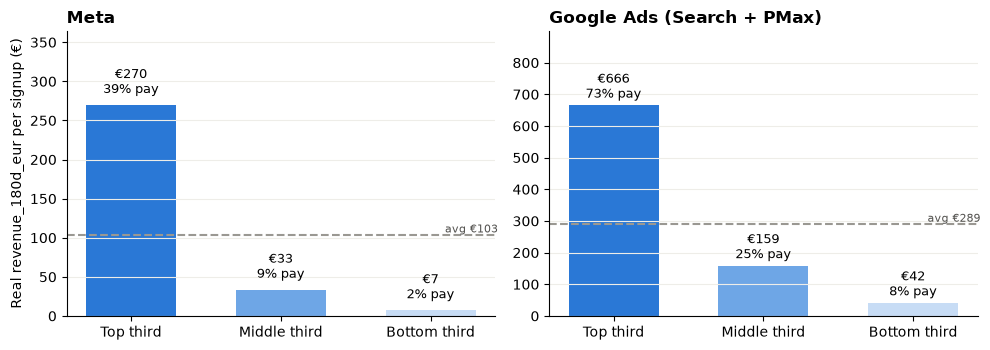

In [13]:
for platform in ["meta","google"]:
    print(f"--- {platform} ---")
    display(thirds(scores[platform], y_paid[test_mask[platform]], y_rev[test_mask[platform]])
            .style.format({"paid_within_30d": "{:.0%}", "real_revenue_per_signup": "€{:.0f}", "predicted_value_per_signup": "€{:.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (platform, title) in zip(axes, [("meta", "Meta"), ("google", "Google Ads (Search + PMax)")]):
    te = test_mask[platform]; t = thirds(scores[platform], y_paid[te], y_rev[te]); avg = y_rev[te].mean()
    bars = ax.bar(np.arange(3), t.real_revenue_per_signup, color=[BLUE, BLUE2, BLUE3], width=0.6)
    for b, v, p in zip(bars, t.real_revenue_per_signup, t.paid_within_30d):
        ax.text(b.get_x() + b.get_width()/2, v + 10, f"€{v:.0f}\n{p:.0%} pay", ha="center", va="bottom", fontsize=9)
    ax.axhline(avg, color=GRAY, ls="--"); ax.text(2.45, avg, f"avg €{avg:.0f}", va="bottom", ha="right", color=INK2, fontsize=8)
    ax.set_xticks(np.arange(3), ["Top third", "Middle third", "Bottom third"]); ax.set_ylim(0, t.real_revenue_per_signup.max() * 1.35)
    ax.set_title(title, loc="left", fontweight="bold"); ax.grid(axis="y", color="#eeede8")
axes[0].set_ylabel("Real revenue_180d_eur per signup (€)"); plt.tight_layout(); plt.show()

The same thing from Meta's point of view: today every signup is sent as equal; with the model each signup carries its own value. The boxes show what the signups in each third look like and what they really brought.

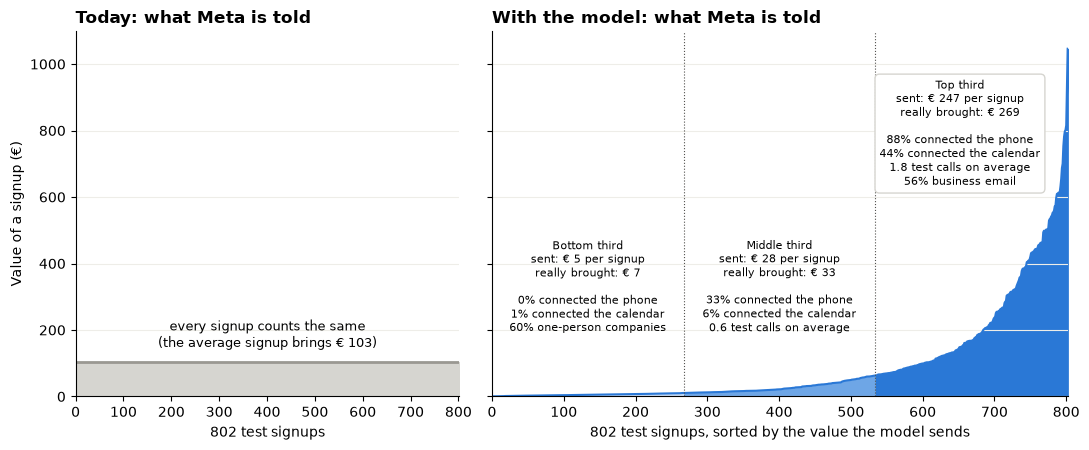

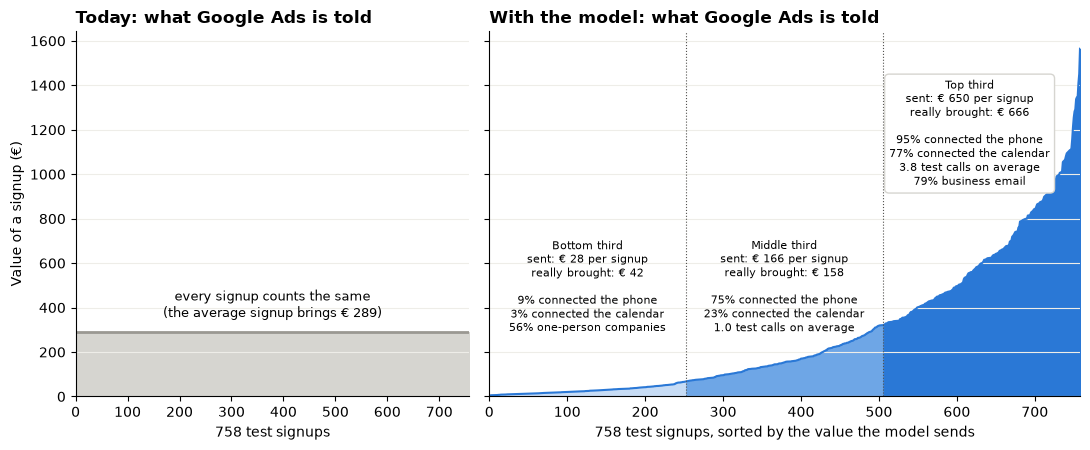

In [14]:
def value_distribution(platform, label):
    te = test_mask[platform]; raw = df.loc[te].copy(); raw["v"] = scores[platform]; raw["solo"] = raw.company_size.eq("1")
    raw = raw.sort_values("v").reset_index(drop=True); n = len(raw); b1, b2 = n // 3, 2 * n // 3
    raw["third"] = np.where(raw.index < b1, "bottom", np.where(raw.index < b2, "middle", "top"))
    prof = raw.groupby("third").agg(v=("v", "mean"), rev=("revenue_180d_eur", "mean"), ph=("phone_connected_24h", "mean"),
                                    cal=("calendar_connected_72h", "mean"), tc=("test_calls_72h", "mean"), be=("business_email", "mean"), solo=("solo", "mean"))
    today = raw.revenue_180d_eur.mean(); ymax = max(raw.v.max() * 1.05, 400); x = np.arange(1, n + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, gridspec_kw={"width_ratios": [1, 1.5]})
    ax = axes[0]; ax.fill_between(x, 0, today, color="#d6d5d0"); ax.plot(x, np.full(n, today), color=GRAY, lw=2)
    ax.text(n/2, today + ymax*0.03, f"every signup counts the same\n(the average signup brings € {today:.0f})", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Today: what {label} is told", loc="left", fontweight="bold"); ax.set_xlabel(f"{n} test signups"); ax.set_ylabel("Value of a signup (€)")
    ax.set_xlim(0, n); ax.set_ylim(0, ymax); ax.grid(axis="y", color="#eeede8")
    ax = axes[1]
    for lo, hi, col in [(0, b1, BLUE3), (b1, b2, BLUE2), (b2, n, BLUE)]: ax.fill_between(x[lo:hi], 0, raw.v.values[lo:hi], color=col)
    ax.plot(x, raw.v.values, color=BLUE, lw=1.5)
    for xx in (b1, b2): ax.axvline(xx, color=INK2, lw=0.8, ls=":")
    def txt(third, cx, cy, extra, box=False):
        p = prof.loc[third]
        ax.text(cx, cy, f"{third.capitalize()} third\nsent: € {p.v:.0f} per signup\nreally brought: € {p.rev:.0f}\n\n{p.ph:.0%} connected the phone\n{p.cal:.0%} connected the calendar\n{extra}",
                ha="center", va="center", fontsize=8, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#d6d5d0") if box else None)
    txt("bottom", b1/2, ymax*0.30, f"{prof.loc['bottom'].solo:.0%} one-person companies")
    txt("middle", (b1+b2)/2, ymax*0.30, f"{prof.loc['middle'].tc:.1f} test calls on average")
    txt("top", (b2+n)/2 - n*0.02, ymax*0.72, f"{prof.loc['top'].tc:.1f} test calls on average\n{prof.loc['top'].be:.0%} business email", box=True)
    ax.set_title(f"With the model: what {label} is told", loc="left", fontweight="bold"); ax.set_xlabel(f"{n} test signups, sorted by the value the model sends")
    ax.set_xlim(0, n); ax.grid(axis="y", color="#eeede8"); plt.tight_layout(); plt.show()

value_distribution("meta", "Meta")
value_distribution("google", "Google Ads")

### 4c. Can the euro number be trusted? (calibration)

The platforms will treat our value as money and compute return on ad spend from it. So when the model says "€ 300", those signups should really bring about € 300 on average. We split the test signups into five groups by predicted value and compare the average prediction with the average real revenue.

--- meta ---


,signups,model_said,really_brought
bin,,,
0,161,€3,€8
1,160,€9,€16
2,160,€25,€36
3,160,€80,€63
4,161,€348,€392


--- google ---


,signups,model_said,really_brought
bin,,,
0,152,€17,€31
1,151,€57,€61
2,152,€158,€168
3,151,€366,€351
4,152,€810,€833


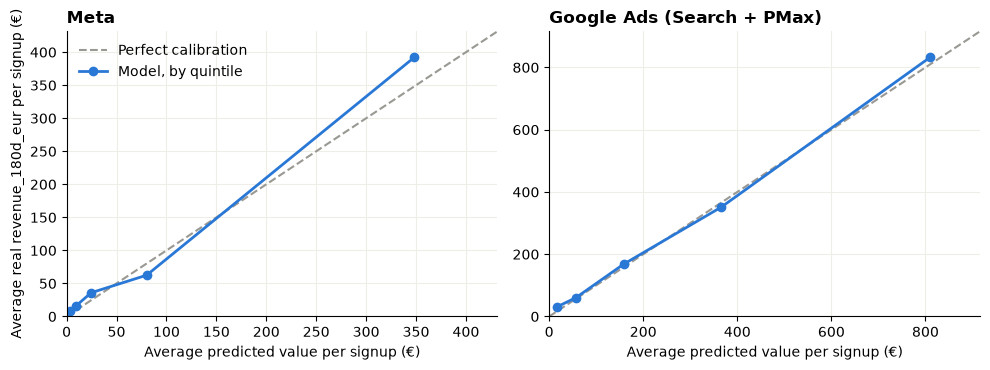

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (platform, title) in zip(axes, [("meta", "Meta"), ("google", "Google Ads (Search + PMax)")]):
    te = test_mask[platform]; c = calibration(scores[platform], y_rev[te])
    print(f"--- {platform} ---"); display(c.style.format({"model_said": "€{:.0f}", "really_brought": "€{:.0f}"}))
    m = max(c.model_said.max(), c.really_brought.max()) * 1.1
    ax.plot([0, m], [0, m], color=GRAY, ls="--", label="Perfect calibration"); ax.plot(c.model_said, c.really_brought, color=BLUE, lw=2, marker="o", label="Model, by quintile")
    ax.set_xlim(0, m); ax.set_ylim(0, m); ax.set_xlabel("Average predicted value per signup (€)"); ax.set_title(title, loc="left", fontweight="bold"); ax.grid(color="#eeede8")
axes[0].set_ylabel("Average real revenue_180d_eur per signup (€)"); axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

Both models are close to the diagonal; on average the Meta model is about 10% conservative (€ 93 predicted vs € 103 real), Google within 3%.

### 4d. The weights: what the models actually learned

Four tables: for each platform, step 1 ("will they pay?") and step 2 ("if they pay, how much?"). Positive = pushes the number up. Weights are comparable within a table because every feature was put on the same scale before training.

In [16]:
w = pd.DataFrame({("Meta", "step 1: will pay?"): models["meta"].coefficients(), ("Meta", "step 2: € if pays"): models["meta"].coefficients_stage2(),
                  ("Google Ads", "step 1: will pay?"): models["google"].coefficients(), ("Google Ads", "step 2: € if pays"): models["google"].coefficients_stage2()})
w = w[~w.index.str.startswith("channel_")].sort_values(("Meta", "step 1: will pay?"), ascending=False)
w.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1, subset=[("Meta","step 1: will pay?"),("Google Ads","step 1: will pay?")])

Reading the table: what people **do** in the first three days (phone, test calls, calendar) matters most; what they **are** (industry, company size) matters too but less. A one-person automotive business on mobile that did nothing is the lowest-value profile on Meta; a medical or property-management company with 6–20 staff that connected everything is the highest.

## 5. Other checks we made on the way

**One model for all channels instead of two?** We trained a model on all 6,000 signups and then asked it to score only the Meta test signups (and only the Google ones). Ranking quality is the same. But without the channel as an input, the all-channel model gets the euro level wrong: it predicts about € 124 per Meta signup where the truth is € 103 (+20%), and € 254 for Google where the truth is € 289. Separate models avoid this without extra assumptions.

In [17]:
rows = []
for platform in ["meta","google"]:
    te = test_mask[platform]
    for label, inc in [("all channels, channel as input", True), ("all channels, no channel input", False)]:
        X = feature_frame(df, "72h", include_channel=inc)
        s = LeadValueModel().fit(X[train], y_paid[train], y_rev[train]).predict_value(X[te])
        r = summary(s, y_paid[te], y_rev[te]); rows.append({"scored platform": platform, "model": label, "revenue in top 30%": r["revenue_top30"], "model said (avg €)": r["predicted_mean"], "really (avg €)": r["actual_mean"]})
    r = summary(scores[platform], y_paid[te], y_rev[te]); rows.append({"scored platform": platform, "model": "separate per platform (chosen)", "revenue in top 30%": r["revenue_top30"], "model said (avg €)": r["predicted_mean"], "really (avg €)": r["actual_mean"]})
pd.DataFrame(rows).set_index(["scored platform","model"]).style.format({"revenue in top 30%": "{:.0%}", "model said (avg €)": "€{:.0f}", "really (avg €)": "€{:.0f}"})

**Google Search and PMax: one model or two?** Both are campaign types inside the same Google Ads account and bid on the same conversion action, so one model is simpler. We checked anyway: a PMax-only model has just 545 training signups and is not better than the joint model, which already knows whether a signup came from Search or PMax.

In [18]:
rows = []
for ch in ["google_search", "google_pmax"]:
    cm = df.channel.eq(ch).values; tr, te = train & cm, test & cm
    own = LeadValueModel().fit(X72[tr], y_paid[tr], y_rev[tr]).predict_value(X72[te]); joint = models["google"].predict_value(X72[te])
    for name, s in [("own model", own), ("one Google Ads model", joint)]:
        r = summary(s, y_paid[te], y_rev[te]); rows.append({"channel": ch, "model": name, "training signups": int(tr.sum()), "revenue in top 30%": r["revenue_top30"], "model said (avg €)": r["predicted_mean"], "really (avg €)": r["actual_mean"]})
pd.DataFrame(rows).set_index(["channel","model"]).style.format({"revenue in top 30%": "{:.0%}", "model said (avg €)": "€{:.0f}", "really (avg €)": "€{:.0f}"})

**A fancier algorithm?** We also tried gradient boosting (many small decision trees) and a one-step variant (chance of paying × one average revenue for everybody). Neither beats the two-step logistic model on 1,500-1,800 training signups, and the logistic model is the only one whose weights can be printed and sanity-checked by a marketer. So we keep it.

In [19]:
rows = []
for platform in ["meta","google"]:
    tr, te = train & channel_mask(df, platform), test_mask[platform]
    for label, kw in [("two-step logistic + ridge (chosen)", {}), ("one-step: P(pay) × average payer revenue", dict(stage2="const")), ("gradient boosting, two steps", dict(stage1="gbm", stage2="gbm"))]:
        s = LeadValueModel(**kw).fit(X72[tr], y_paid[tr], y_rev[tr]).predict_value(X72[te])
        r = summary(s, y_paid[te], y_rev[te]); rows.append({"platform": platform, "model": label, "revenue in top 30%": r["revenue_top30"], "model said (avg €)": r["predicted_mean"], "really (avg €)": r["actual_mean"]})
pd.DataFrame(rows).set_index(["platform","model"]).style.format({"revenue in top 30%": "{:.0%}", "model said (avg €)": "€{:.0f}", "really (avg €)": "€{:.0f}"})

## 6. Decisions

| Question from the task | Decision |
|---|---|
| Features used | country, industry, company_size, device, business_email, signup_hour, signup_date (weekday), phone_connected_24h, assistant_configured_24h, test_calls_72h, calendar_connected_72h, plus our own paid_by_72h and plan_by_72h |
| Features left out | `minutes_used_7d` (after 7 days), `onboarding_call_booked` (no timestamp), `converted_paid_30d` and `revenue_180d_eur` (after 30 / 180 days, the answers), `plan_selected` and `days_to_first_payment` (filled in only after a payment) |
| Model | Two models (Meta; Google Ads = Search + PMax). Each: logistic regression "will they pay?" × ridge regression "how much if they pay?" → expected 180-day revenue in EUR. Organic and referral are not used. |
| When to score | 72 hours after signup |
| Validation | trained on Oct 2025 – Jan 2026, tested on Feb – Mar 2026; compared with "every signup the same" |
| Result | the 30% of signups with the highest predicted value bring about 85% (Meta) / 74% (Google) of revenue vs 30% today; predicted euros within 10% of real euros |
| In production | the formula is applied every day to signups that turned 72h old; it is re-trained once a month on the latest signups whose outcomes are known, and replaced only if it beats the current one on the last two months |